In [23]:
import geopandas as gpd
from pathlib import Path
import pandas as pd
import contextily as cx

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib_scalebar.scalebar import ScaleBar

import rasterio
from rasterio.plot import show
from rasterio.warp import calculate_default_transform, reproject, Resampling

dossier = r"C:\Users\Antonin\Studies\M2\Enjeux_Climatique\EXAM_2025_2026"

In [ ]:
communes = gpd.read_file(dossier + r"\communes.gpkg")
communes.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 630 entries, 0 to 629
Data columns (total 27 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ID          630 non-null    object        
 1   INSEE_COM   630 non-null    object        
 2   INSEE_CAN   630 non-null    object        
 3   INSEE_ARR   630 non-null    object        
 4   INSEE_COL   630 non-null    object        
 5   INSEE_DEP   630 non-null    object        
 6   INSEE_REG   630 non-null    object        
 7   POPULATION  630 non-null    int32         
 8   SUPERF_CAD  630 non-null    int32         
 9   DATE_CREAT  630 non-null    object        
 10  DATE_MAJ    630 non-null    object        
 11  DATE_APP    45 non-null     datetime64[ms]
 12  DATE_CONF   9 non-null      datetime64[ms]
 13  CODE_POST   630 non-null    object        
 14  NOM         630 non-null    object        
 15  CL_ARROND   630 non-null    object        
 16  CL_COLLTER  630 no

In [17]:
batiments = gpd.read_file(dossier + r"\batiments.gpkg")
batiments.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 101508 entries, 0 to 101507
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   ID          101508 non-null  object  
 1   USAGE1      101508 non-null  object  
 2   NB_ETAGES   45989 non-null   float64 
 3   MAT_TOITS   42319 non-null   object  
 4   HAUTEUR     99954 non-null   float64 
 5   Z_MIN_SOL   100552 non-null  float64 
 6   Z_MAX_TOIT  87034 non-null   float64 
 7   geometry    101508 non-null  geometry
dtypes: float64(4), geometry(1), object(3)
memory usage: 6.2+ MB


In [20]:
with rasterio.open(dossier + r"\TempeteMartinWGS84.tif") as src:
    data = src.read(1, masked=True)
    resume_tif = pd.DataFrame({
        "CRS": [str(src.crs)],
        "Dimensions (L x C)": [f"{src.height} x {src.width}"],
        "Résolution": [str(src.res)],
        "Valeur Min": [round(float(data.min()), 2)],
        "Valeur Max": [round(float(data.max()), 2)],
        "Moyenne": [round(float(data.mean()), 2)]
    })

resume_tif

,CRS,Dimensions (L x C),Résolution,Valeur Min,Valeur Max,Moyenne
0,EPSG:4326,2400 x 3600,"(0.016666666666666666, 0.016666666666666666)",11.91,52.24,19.89


In [26]:
# --- 1. PRÉPARATION ET HARMONISATION DES CRS (vers EPSG:3857) ---
crs_cible = "EPSG:3857"
communes_3857 = communes.to_crs(crs_cible)

fichier_source = dossier + r"\TempeteMartinWGS84.tif"
fichier_reprojete = dossier + r"\TempeteMartin_3857.tif"  # <-- Nouveau nom différent !

with rasterio.open(fichier_source) as src:
    transform, width, height = calculate_default_transform(
        src.crs, crs_cible, src.width, src.height, *src.bounds
    )
    kwargs = src.meta.copy()
    kwargs.update({
        "crs": crs_cible,
        "transform": transform,
        "width": width,
        "height": height
    })

    # Création du nouveau fichier reprojeté sans toucher à l'original
    with rasterio.open(fichier_reprojete, "w", **kwargs) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs=crs_cible,
            resampling=Resampling.bilinear
        )

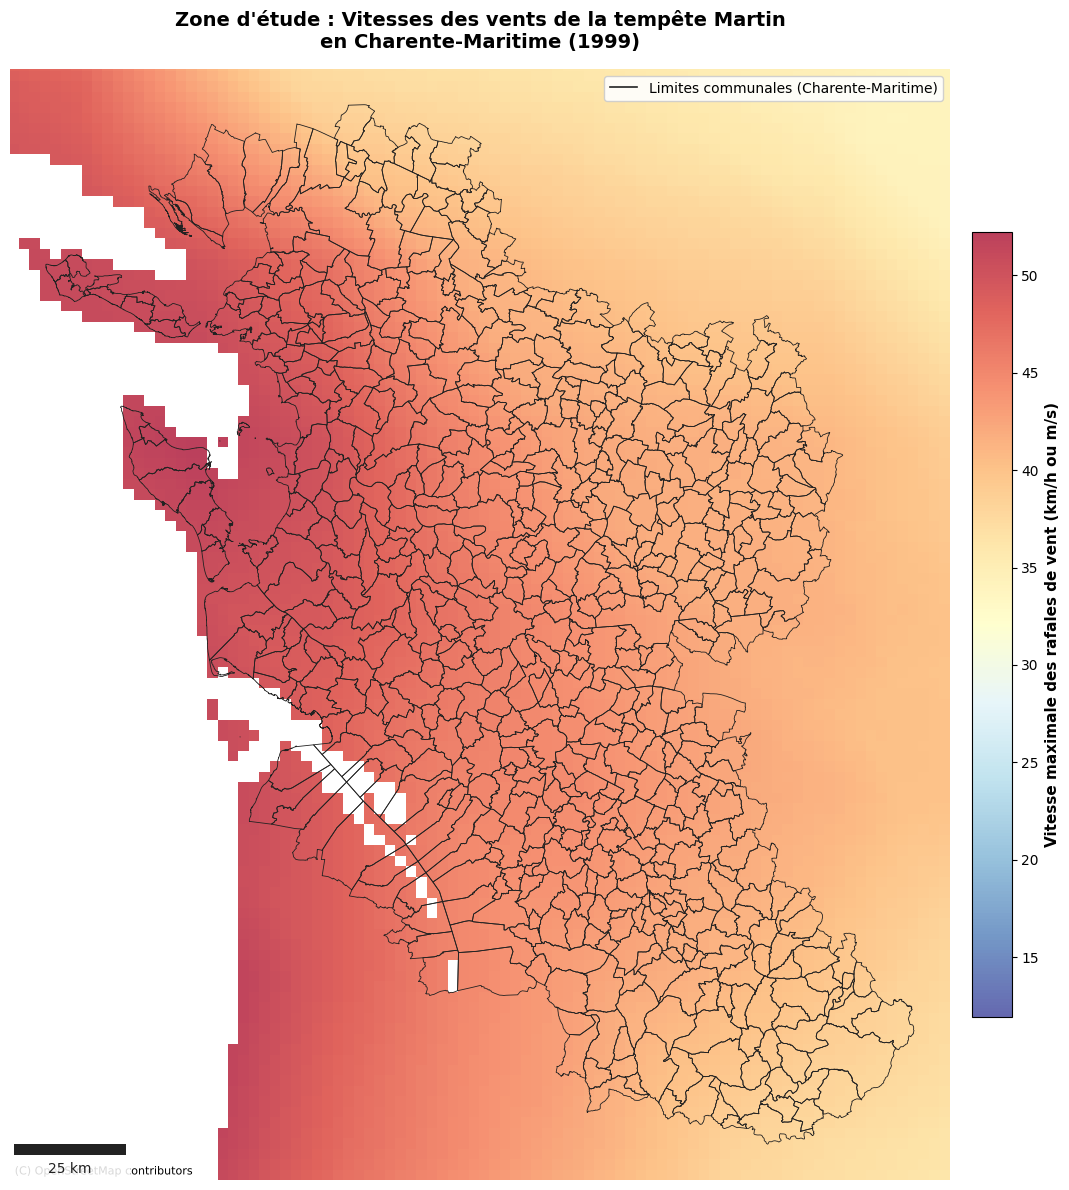

In [28]:
# --- 2. CRÉATION DE LA CARTE ---
fig, ax = plt.subplots(figsize=(12, 12))

# A. Affichage du raster des vitesses de vent (palette bleu -> rouge : 'RdYlBu_r' ou 'jet' ou 'coolwarm')
with rasterio.open(fichier_reprojete) as src_3857:
    # Récupération de l'image pour pouvoir créer la barre de couleur (colorbar)
    img_vent = show(
        src_3857,
        ax=ax,
        cmap="RdYlBu_r",  # Bleu (faible) -> Jaune -> Rouge (fort)
        alpha=0.75,       # Légère transparence pour voir le relief/côtes OSM en dessous
        zorder=2
    )

# B. Ajout du fond de carte OpenStreetMap (en arrière-plan : zorder=1)
cx.add_basemap(
    ax,
    crs=crs_cible,
    source=cx.providers.OpenStreetMap.Mapnik,
    zorder=1
)

# C. Affichage des communes en transparence (contours uniquement : facecolor="none")
communes_3857.plot(
    ax=ax,
    facecolor="none",      # Intérieur totalement transparent
    edgecolor="#222222",   # Contours gris très foncé
    linewidth=0.6,
    zorder=3
)

# Cadrer la carte sur l'emprise des communes de Charente-Maritime (avec une petite marge)
minx, miny, maxx, maxy = communes_3857.total_bounds
marge = 8000  # 8 km de marge
ax.set_xlim(minx - marge, maxx + marge)
ax.set_ylim(miny - marge, maxy + marge)

# --- 3. ÉLÉMENTS CARTOGRAPHIQUES (Titre, Légende, Échelle) ---

# Barre de couleur pour les vitesses de vent
cbar = plt.colorbar(img_vent.get_images()[0], ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Vitesse maximale des rafales de vent (km/h ou m/s)", fontsize=11, fontweight="bold")

# Légende pour les contours communaux
legende_elements = [
    Line2D([0], [0], color="#222222", lw=1.2, label="Limites communales (Charente-Maritime)")
]
ax.legend(handles=legende_elements, loc="upper right", frameon=True, facecolor="white", framealpha=0.9)

# Barre d'échelle (1 mètre = 1 unité en EPSG:3857)
scalebar = ScaleBar(
    dx=1,
    units="m",
    location="lower left",
    box_alpha=0.85,
    color="#222222"
)
ax.add_artist(scalebar)

# Titre et nettoyage des axes
ax.set_title(
    "Zone d'étude : Vitesses des vents de la tempête Martin\nen Charente-Maritime (1999)",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_axis_off()

plt.tight_layout()
plt.savefig("carte_zone_etude_tempete_martin.png", dpi=300, bbox_inches="tight")
plt.show()